## EDA-EXPLORATORY DATA ANALYSIS

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
from sklearn.preprocessing import StandardScaler,LabelEncoder,OneHotEncoder,OrdinalEncoder
import matplotlib.pyplot as plt
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import FunctionTransformer
import pickle
import warnings
warnings.filterwarnings('ignore')

In [2]:
df=pd.read_csv("loan_approved.csv")

In [3]:
df.head()

,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status (Approved)
0,LP001002,Male,No,0,Graduate,No,5849,0.0,NaN,360.0,1.0,Urban,Y
1,LP001003,Male,Yes,1,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,N
2,LP001005,Male,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,Y
3,LP001006,Male,Yes,0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban,Y
4,LP001008,Male,No,0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban,Y


In [4]:
df.isnull().sum()

Loan_ID                    0
Gender                    13
Married                    3
Dependents                15
Education                  0
Self_Employed             32
ApplicantIncome            0
CoapplicantIncome          0
LoanAmount                22
Loan_Amount_Term          14
Credit_History            50
Property_Area              0
Loan_Status (Approved)     0
dtype: int64

### Imputing the null values:

In [5]:
df['Gender'].value_counts()         #The mode is used to replace null values from categorical column (here mode is "Male")

Gender
Male      489
Female    112
Name: count, dtype: int64

In [6]:
df.loc[df['Gender'].isnull(),'Gender']="Male"       #Replacing all the null values with "Male" 

In [7]:
df.Gender.isnull().sum()

np.int64(0)

In [8]:
df['Credit_History'].value_counts()   

Credit_History
1.0    475
0.0     89
Name: count, dtype: int64

In [9]:
df.loc[df['Credit_History'].isnull(),'Credit_History']=0.0

In [10]:
df.Credit_History.isnull().sum()

np.int64(0)

In [11]:
df.loc[df['LoanAmount'].isnull(),'LoanAmount']=df['LoanAmount'].median()

In [12]:
df.LoanAmount.isnull().sum()

np.int64(0)

In [13]:
df['Married'].value_counts()

Married
Yes    398
No     213
Name: count, dtype: int64

In [14]:
df.loc[df['Married'].isnull(),'Married']="Yes"

In [15]:
df.Married.isnull().sum()

np.int64(0)

In [16]:
df['Dependents'].value_counts()

Dependents
0     345
1     102
2     101
3+     51
Name: count, dtype: int64

In [17]:
df.loc[df['Dependents'].isnull(),'Dependents']=0.0

In [18]:
df.Dependents.isnull().sum()

np.int64(0)

In [19]:
df['Self_Employed'].value_counts()

Self_Employed
No     500
Yes     82
Name: count, dtype: int64

In [20]:
df.loc[df['Self_Employed'].isnull(),'Self_Employed']="No"

In [21]:
df.Self_Employed.isnull().sum()

np.int64(0)

In [22]:
df['Loan_Amount_Term'].value_counts()

Loan_Amount_Term
360.0    512
180.0     44
480.0     15
300.0     13
240.0      4
84.0       4
120.0      3
60.0       2
36.0       2
12.0       1
Name: count, dtype: int64

In [23]:
df.loc[df['Loan_Amount_Term'].isnull(),'Loan_Amount_Term']=360.0

In [24]:
df.Loan_Amount_Term.isnull().sum()

np.int64(0)

In [25]:
df.isnull().sum()

Loan_ID                   0
Gender                    0
Married                   0
Dependents                0
Education                 0
Self_Employed             0
ApplicantIncome           0
CoapplicantIncome         0
LoanAmount                0
Loan_Amount_Term          0
Credit_History            0
Property_Area             0
Loan_Status (Approved)    0
dtype: int64

### Visualising the outliers

<Axes: xlabel='LoanAmount'>

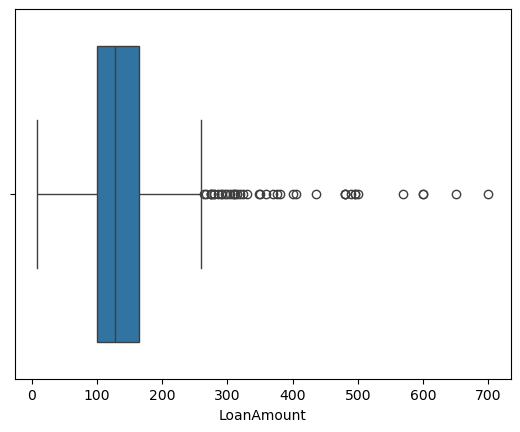

In [26]:
sns.boxplot(x=df.LoanAmount,orient='h')

<Axes: xlabel='ApplicantIncome'>

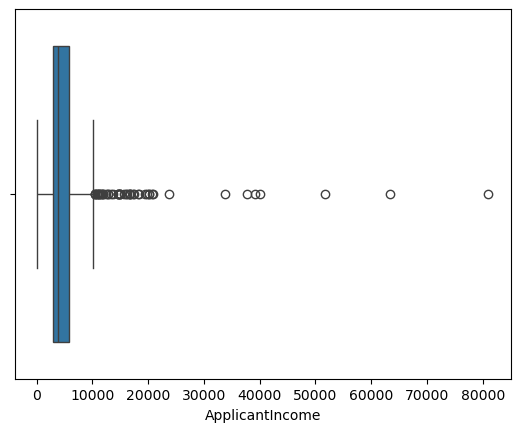

In [27]:
sns.boxplot(x=df.ApplicantIncome,orient='h')

In [28]:
from scipy.stats.mstats import winsorize

#Specify the percentage of data to be trimmed from both ends
trim_percentage=0.08

#Winsorize the specified column
df['ApplicantIncome']=winsorize(df['ApplicantIncome'],limits=trim_percentage)

<Axes: xlabel='ApplicantIncome'>

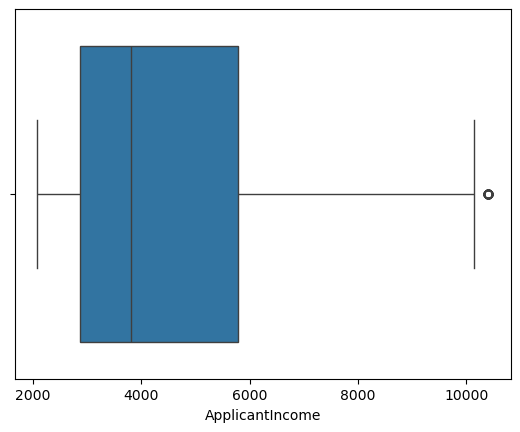

In [29]:
sns.boxplot(x=df.ApplicantIncome, orient='h')

### Using IQR method to handle the outlier

In [30]:
#Calculate Quartiles
Q1 = df['LoanAmount'].quantile(0.25)
Q3 = df['LoanAmount'].quantile(0.75)

In [31]:
#Calculate QR
IQR = Q3 - Q1
IQR

np.float64(64.5)

In [32]:
#Define lower and upper bounds
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q1 + 1.5 * IQR

In [33]:
print(lower_bound)
print(upper_bound)

3.5
197.0


In [34]:
#Reomove the Outliers
df = df[(df['LoanAmount'] >= lower_bound) & (df['LoanAmount'] <= upper_bound)]

<Axes: xlabel='LoanAmount'>

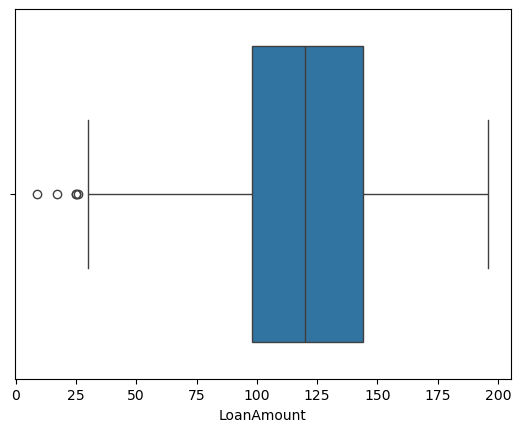

In [35]:
sns.boxplot(x=df.LoanAmount,orient='h')

## ENCODING TECHNIQUES AND TYPES:

### ONE HOT ENCODING:

In [5]:
df_encoded = pd.get_dummies(df,columns=['Married'], prefix='Married')

In [37]:
df_encoded.columns

Index(['Loan_ID', 'Gender', 'Dependents', 'Education', 'Self_Employed',
       'ApplicantIncome', 'CoapplicantIncome', 'LoanAmount',
       'Loan_Amount_Term', 'Credit_History', 'Property_Area',
       'Loan_Status (Approved)', 'Married_No', 'Married_Yes'],
      dtype='object')

### LABEL ENCODING :

In [38]:
from sklearn.preprocessing import LabelEncoder
encoder = LabelEncoder()

# Fit and transform the 'matchType' column to obtain label-encoded values
df['Married'] = encoder.fit_transform(df['Married'])

#Display the result
print(df[['Married']])

     Married
0          0
1          1
2          1
3          1
4          0
..       ...
608        1
609        0
610        1
612        1
613        0

[529 rows x 1 columns]


In [39]:
from sklearn.preprocessing import LabelEncoder
encoder = LabelEncoder()

# Fit and transform the 'matchType' column to obtain label-encoded values
df['Loan_Status (Approved)'] = encoder.fit_transform(df['Loan_Status (Approved)'])

#Display the result
print(df[['Loan_Status (Approved)']])

     Loan_Status (Approved)
0                         1
1                         0
2                         1
3                         1
4                         1
..                      ...
608                       1
609                       1
610                       1
612                       1
613                       0

[529 rows x 1 columns]


### ORDINAL ENCODING :

In [40]:
df.Education.value_counts()

Education
Graduate        399
Not Graduate    130
Name: count, dtype: int64

In [41]:
Education_enc=OrdinalEncoder(categories=[['Graduate','Not Graduate']])

In [42]:
df['Education'] = encoder.fit_transform(df[['Education']])

In [43]:
df.Education.value_counts()

Education
0    399
1    130
Name: count, dtype: int64

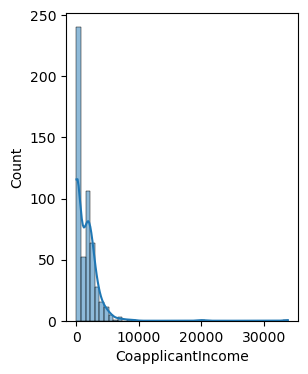

In [45]:
plt.figure(figsize=(3,4))
sns.histplot(x=df['CoapplicantIncome'],kde=True)
plt.show()

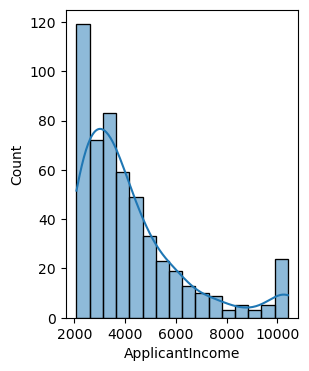

In [46]:
plt.figure(figsize=(3,4))
sns.histplot(x=df['ApplicantIncome'],kde=True)
plt.show()

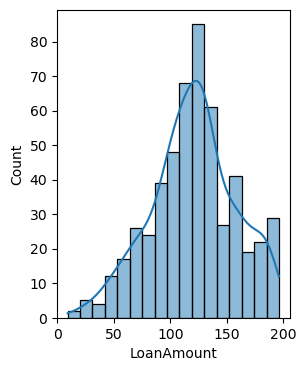

In [47]:
plt.figure(figsize=(3,4))
sns.histplot(x=df['LoanAmount'],kde=True)
plt.show()

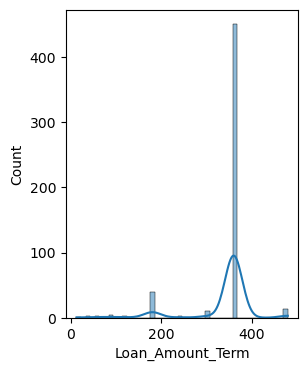

In [48]:
plt.figure(figsize=(3,4))
sns.histplot(x=df['Loan_Amount_Term'],kde=True)
plt.show()

## Log Transformation: 

### Used to reduce right-skewness in data and make the distribution more symmetrical.

In [49]:
df['CoapplicantIncome'] = np.log(df['CoapplicantIncome'])

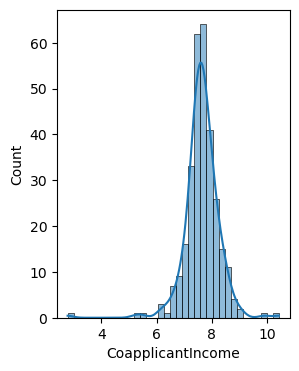

In [50]:
plt.figure(figsize=(3,4))
sns.histplot(x=df['CoapplicantIncome'],kde=True)
plt.show()

### Exponential Transformation:

In [51]:
df['ApplicantIncome'] = df.ApplicantIncome**(1/1.2)

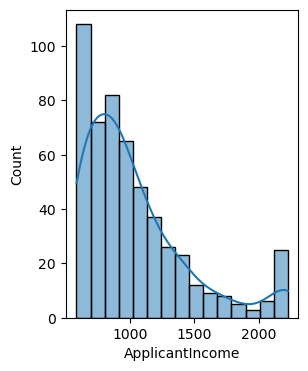

In [52]:
plt.figure(figsize=(3,4))
sns.histplot(x=df['ApplicantIncome'],kde=True)
plt.show()

## Square Root Transformation: 

### Square root transformation is a technique used to reduce positive skewness in numerical data.

In [53]:
df['LoanAmount'] = df.LoanAmount**(1/2)

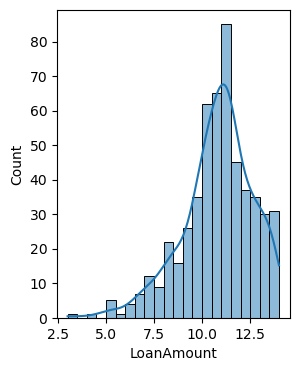

In [54]:
plt.figure(figsize=(3,4))
sns.histplot(x=df['LoanAmount'],kde=True)
plt.show()

## Box Cox Transformation:  

### Box-Cox transformation is a statistical technique used to make numerical data more normally distributed and reduce skewness.It finds an optimal parameter called Lambda (λ) to transform the data.

In [61]:
from scipy.stats import boxcox
transformed_data, lambda_value = boxcox(df['Loan_Amount_Term'])

In [57]:
#print("Transformed data:",transformed_data)

In [62]:
print("Lambda value:",lambda_value)

Lambda value: 2.9557432692891683


## Scaling Techniques

### 1. Standard Scalar:

In [6]:
df.columns

Index(['Loan_ID', 'Gender', 'Married', 'Dependents', 'Education',
       'Self_Employed', 'ApplicantIncome', 'CoapplicantIncome', 'LoanAmount',
       'Loan_Amount_Term', 'Credit_History', 'Property_Area',
       'Loan_Status (Approved)'],
      dtype='object')

In [7]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
ApplicantIncome_scaled = scaler.fit_transform(df[['ApplicantIncome']])

In [9]:
 ApplicantIncome_scaled

array([[ 7.29908229e-02],
       [-1.34411954e-01],
       [-3.93747337e-01],
       [-4.62062470e-01],
       [ 9.77284368e-02],
       [ 2.21831139e-03],
       [-5.03018784e-01],
       [-3.87849628e-01],
       [-2.28939128e-01],
       [ 1.21845703e+00],
       [-3.60982286e-01],
       [-4.75659966e-01],
       [-3.81788093e-01],
       [-5.81654908e-01],
       [-6.72414101e-01],
       [-7.42880841e-02],
       [-2.96107483e-01],
       [-3.10196456e-01],
       [-8.46090753e-02],
       [-4.59277440e-01],
       [ 3.69678365e-01],
       [ 9.03563002e-02],
       [-4.59277440e-01],
       [-3.33951118e-01],
       [-2.76284627e-01],
       [ 6.80946355e-01],
       [-4.26676214e-01],
       [-1.92897571e-01],
       [-6.48987089e-01],
       [-2.70878394e-01],
       [-2.02727086e-01],
       [-3.66388519e-01],
       [-1.16555001e-01],
       [-3.11834708e-01],
       [ 1.16259261e+00],
       [-5.12520649e-01],
       [-5.85750540e-01],
       [-2.84475890e-01],
       [-2.0

### 2. MinMax Scalar

In [10]:
from sklearn.preprocessing import MinMaxScaler

#define the MinMaxScaler object
scaler = MinMaxScaler()
ApplicantIncome_scaled2=scaler.fit_transform(df[['ApplicantIncome']])

### 3. Robust Scaler

In [12]:
from sklearn.preprocessing import RobustScaler
scaler = RobustScaler()
ApplicantIncome_Scaled3 = scaler.fit_transform(df[['ApplicantIncome']])